# Fig. 7: analysis of the final PPO policy.

Styling follows Figs. 3, 4 and 6.
- (a) Contribution of each operating variable: yield lost when that single variable is reset to the recipe in a replay of the 200 evaluation batches (ppo_lever_ablation_ts{0..9}.npz). Bar = mean over seeds, line = seed min-max.
- (b)(c) Policy SHAP: contribution of the 16 observation channels to the sugar-feed (F_s) and PAA-feed (F_PAA) actions (normalised, recipe = 0), from ppo_shap_ts{0,1,2}.npz with the 1,500 decision points of each seed pooled. Top: the five channels with the largest mean |SHAP|, as rows; colour = rank of the channel value (low = slate blue, high = rust), as in Fig. 3d. Below: SHAP of the same five channels against batch progress (%), with dots for the decisions and a line for the mean at each decision time.
- (d) Change from no intervention (%) for online, operating, off-line/state and outcome variables, from stats_all_vars.npy and stats_all_vars_raw.npz.

In [1]:
import sys; sys.path.insert(0, '..')          # repository root, for paths.py
from paths import DATA, OUTD                   # data/ and output/

In [2]:
import numpy as np, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
R = DATA; OUT = OUTD + 'fig7'
INK, GRY, C_PPO = '#23201a', '#8f897d', '#c9a227'
plt.rcParams.update({'font.family': ['DejaVu Sans'], 'font.size': 5.5, 'axes.titlesize': 6.5, 'axes.labelsize': 5.5,
                     'xtick.labelsize': 5.0, 'ytick.labelsize': 5.0, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'mathtext.default': 'regular'})
SEEDS = [0, 1, 2]
SEEDS_LEV = list(range(10))   # (a) uses 10 seeds; SHAP panels (b)(c) use 3 seeds
LEV = ['$F_s$', '$F_{PAA}$', '$F_{oil}$', '$F_g$', '$F_w$', '$F_{dis}$', 'Agitation', 'Pressure', 'pH set-point', 'T set-point']
OBS = ['Dissolved O$_2$', 'pH', 'Temperature', 'Off-gas CO$_2$', 'Off-gas O$_2$', 'Vessel weight', 'Volume',
       '$\\Delta$ dissolved O$_2$ (6 h)', '$\\Delta$ off-gas CO$_2$ (6 h)', 'Sugar feed', 'PAA feed', 'Batch time', 'OUR', 'CER', 'Base flow', 'Coolant flow']
cm = LinearSegmentedColormap.from_list('br', ['#46618a', '#d9d4ca', '#a35a3c'])
def style(a):
    for sp in ('top', 'right'): a.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'): a.spines[sp].set_color(INK)
    a.tick_params(colors=INK)
def title(a, s): a.set_title(s, loc='left', fontweight='bold', color=INK, pad=4)
fig = plt.figure(figsize=(17 / 2.54, 19.5 / 2.54), facecolor='white')  # top row (a)-(c), bottom row (d)
from matplotlib.gridspec import GridSpecFromSubplotSpec
G0 = GridSpec(2, 1, figure=fig, height_ratios=[1.32, 0.98], hspace=0.22, left=0.075, right=0.925, top=0.965, bottom=0.05)
gs = GridSpecFromSubplotSpec(2, 3, subplot_spec=G0[0], width_ratios=[0.8, 1, 1], height_ratios=[0.42, 0.62], wspace=0.55, hspace=0.42)

In [3]:
# (a)
A = np.array([np.load(R + f'ppo_lever_ablation_ts{s}.npz')['yield_'] for s in SEEDS_LEV])      # (seeds, recipe + 10 resets, 200 batches)
loss = np.nanmean(A[:, :1] - A[:, 1:], 2)                                                 # (seeds, 10) mean yield loss per reset variable
o = np.argsort(-loss.mean(0)); aa = fig.add_subplot(gs[:, 0]); style(aa); y = np.arange(10)
aa.barh(y, loss.mean(0)[o], height=0.6, color=C_PPO)
aa.hlines(y, loss.min(0)[o], loss.max(0)[o], color=INK, lw=0.6)
aa.axvline(0, color=GRY, lw=0.4); aa.set_yticks(y); aa.set_yticklabels([LEV[i] for i in o], color=INK); aa.invert_yaxis(); aa.tick_params(axis='y', length=0)
aa.set_xlabel('Yield lost when reset to recipe (kg)', color=INK); title(aa, '(a)')

In [4]:
# (b)(c)
Z = [np.load(R + f'ppo_shap_ts{s}.npz') for s in SEEDS]
PHI = np.concatenate([z['phi'] for z in Z]); X = np.concatenate([z['obs'] for z in Z])
rs = np.random.default_rng(0)
for k, (ai, let) in enumerate(((0, '(b)'), (1, '(c)'))):
    a = fig.add_subplot(gs[0, 1 + k]); style(a); P_ = PHI[:, :, ai]; ord_ = np.argsort(-np.abs(P_).mean(0))
    a.axvline(0, color=GRY, lw=0.4, zorder=1)
    for r, c in enumerate(ord_[:5]):   # top five channels only
        v = P_[:, c]; q = np.argsort(np.argsort(X[:, c])) / (len(v) - 1)
        h, e = np.histogram(v, bins=60); dens = h[np.clip(np.digitize(v, e) - 1, 0, 59)] / h.max()
        jit = (rs.random(len(v)) - .5) * 0.7 * dens; pr = rs.permutation(len(v))
        a.scatter(v[pr], r + jit[pr], c=q[pr], cmap=cm, vmin=0, vmax=1, s=0.5, lw=0, rasterized=True, zorder=2)
    a.set_ylim(4.6, -0.6); a.set_yticks(range(5)); a.set_yticklabels([OBS[c] for c in ord_[:5]], color=INK); a.tick_params(axis='y', length=0)
    lim = np.percentile(np.abs(P_[:, ord_[:5]]), 99.8); a.set_xlim(-lim, lim); a.locator_params(axis='x', nbins=5)
    a.set_xlabel(f'SHAP value for the {"sugar" if ai == 0 else "PAA"}-feed action', color=INK); title(a, let)
    if k == 1:
        cax = a.inset_axes([1.04, 0.12, 0.025, 0.76]); cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cm), cax=cax, ticks=[0, 1]); cb.outline.set_visible(False)
        cb.ax.set_yticklabels(['Low', 'High'], fontsize=4.6, color=INK); cb.ax.tick_params(length=0)
        cb.ax.yaxis.set_ticks_position('right'); cb.set_label('Channel value', fontsize=4.6, color=INK, labelpad=1); cb.ax.yaxis.set_label_position('right')
    # SHAP of the top five channels against batch progress (%): dots = decisions (colour = rank of the channel value), line = mean at each decision time
    TF = np.concatenate([z['tfrac'] for z in Z]) * 100; top = ord_[:5]; r2 = np.random.default_rng(1 + k)   # separate generator, so the scatter of (b)(c) is unchanged
    sg = GridSpecFromSubplotSpec(5, 1, subplot_spec=gs[1, 1 + k], hspace=0.12)
    ut = np.unique(np.round(TF, 2)); MU = np.array([[P_[np.round(TF, 2) == t, c].mean() for t in ut] for c in top])
    ylim = max(np.percentile(np.abs(P_[:, top]), 99.5), 1.15 * np.abs(MU).max())
    for j, c in enumerate(top):
        s_ = fig.add_subplot(sg[j]); style(s_); v = P_[:, c]; q = np.argsort(np.argsort(X[:, c])) / (len(v) - 1); pr = r2.permutation(len(v))
        s_.axhline(0, color=GRY, lw=0.4, zorder=1)
        s_.scatter(TF[pr], v[pr], c=q[pr], cmap=cm, vmin=0, vmax=1, s=0.4, lw=0, rasterized=True, zorder=2)
        s_.plot(ut, MU[j], color=INK, lw=0.7, zorder=3)
        yl = max(np.percentile(np.abs(v), 99.5), 1.15 * np.abs(MU[j]).max())   # own axis for each strip
        tk = float(f'{yl * 0.7:.1g}'); s_.set_xlim(0, 100); s_.set_ylim(-yl, 1.5 * yl); s_.set_yticks([-tk, 0, tk]); 
        lft = v[TF < 35].max() < v[TF > 65].max()   # label over the side where the data are lower
        s_.text(0.015 if lft else 0.985, 0.95, OBS[c], transform=s_.transAxes, ha='left' if lft else 'right', va='top', fontsize=4.8, color=INK, zorder=4,
                bbox=dict(boxstyle='square,pad=0.15', fc='white', ec='none', alpha=0.85))
        if j < 4: s_.tick_params(axis='x', labelbottom=False)
        else: s_.set_xlabel('Batch progress (%)', color=INK)
        if j == 2: s_.set_ylabel('SHAP value', color=INK)

In [5]:
# (d) Dot plot of change from no intervention (%), from stats_all_vars{.npy,_raw.npz}
#     (BO = mean over 10 repeated runs of the estimated-PAA BO controller)
raw = np.load(R + 'stats_all_vars_raw.npz'); ST = {r['name']: r for r in np.load(R + 'stats_all_vars.npy', allow_pickle=True)}
COLD = {'APC': '#8a3324', 'BO': '#2a7f7a', 'PPO': C_PPO, 'CEM': '#1f4e79'}   # BO = estimated PAA + BO, batch mean over 10 repeats
GROUPS = [('Online measurements', '1 Online', [('DO2 (end)', 'Dissolved O$_2$ (mg L$^{-1}$)'), ('Off-gas CO2 (end)', 'Off-gas CO$_2$ (%)'),
                                                ('Volume (end)', 'Broth volume (m$^3$)')]),
          ('Operating variables', '2 Operating', [('Sugar feed (total)', 'Sugar feed, total (L)'), ('PAA feed (total)', 'PAA feed, total (L)'),
                                                  ('__other__', 'Other eight variables')]),
          ('Off-line and unmeasured states', '3 Off-line/state', [('Glucose (end)', 'Glucose (g L$^{-1}$)'), ('PAA (end)', 'PAA, end (mg L$^{-1}$)'),
                                                                  ('PAA (min after 10 h)', 'PAA, minimum (mg L$^{-1}$)'), ('NH3 (end)', 'NH$_3$ (mg L$^{-1}$)'),
                                                                  ('Dissolved CO2 (end)', 'Dissolved CO$_2$ (g L$^{-1}$)'), ('Viscosity (end)', 'Viscosity (cP)')]),
          ('Outcome', '3 Off-line/state', [('Biomass (end, kg)', 'Biomass (kg)'), ('Net yield (incl. removed)', 'Penicillin yield (kg)')])]   # outcome group
OTHER = ['Oil feed (total)', 'Water addition (total)', 'Discharge (total)', 'Aeration (mean)', 'Agitation (mean)', 'Pressure (mean)', 'pH set-point (mean)', 'T set-point (mean)']
rr = np.random.default_rng(0)
def rel(cat, name, arm):
    b = raw[f'{cat}|{name}|None']; a_ = raw[f'{cat}|{name}|{arm}']; ok = np.isfinite(a_) & np.isfinite(b) & (np.abs(b) > 1e-9)
    a_, b = a_[ok], b[ok]; I = rr.integers(0, len(a_), (5000, len(a_)))
    bs = (a_[I].mean(1) - b[I].mean(1)) / np.abs(b[I].mean(1)) * 100
    return (a_.mean() - b.mean()) / abs(b.mean()) * 100, *np.percentile(bs, [2.5, 97.5])
def star(p): return '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < .05 else 'n.s.'
XL, XR = -105, 65
rows = []; yy_ = 0; heads = []
for gname, cat, items in GROUPS:
    heads.append((yy_, gname)); yy_ += 1
    for key, lab in items: rows.append((yy_, '4 Derived' if key == 'Net yield (incl. removed)' else cat, key, lab)); yy_ += 1   # yield is reported as a derived quantity
    yy_ += .35
pos = G0[1].get_position(fig); ad = fig.add_axes([0.28, pos.y0, 0.43, pos.height])
style(ad)                                                                        # same axis style as Figs. 3, 4 and 6
ad.axvline(0, color=GRY, lw=0.4, zorder=2)
OFF = {'APC': -.27, 'BO': -.09, 'PPO': .09, 'CEM': .27}; OTH = {}
from matplotlib.transforms import blended_transform_factory
_trR = blended_transform_factory(ad.transAxes, ad.transData)
for yy, cat, key, lab in rows:
    if key == '__other__':
        mx = max(abs(rel('2 Operating', n, a_)[0]) for n in OTHER for a_ in COLD)
        ad.text(1.03, yy, f'all within ±{mx:.1f} %', transform=_trR, va='center', ha='left', fontsize=5.0, color=INK); continue
    for arm in COLD:
        m, lo, hi = rel(cat, key, arm); yv = yy + OFF[arm]
        if m > XR:
            ad.plot(XR, yv, marker='>', ms=3.2, color=COLD[arm], ls='none', clip_on=False, zorder=5)
            continue                                                    # off-axis values: arrow marker only (values given in the caption)
        ad.plot([max(lo, XL), min(hi, XR)], [yv, yv], color=COLD[arm], lw=0.8, zorder=3)
        ad.plot(m, yv, marker='o', ms=2.8, mfc=COLD[arm] if arm != 'CEM' else 'white', mec=COLD[arm], mew=0.7, ls='none', zorder=4)
    r = ST[key]
    for ci, (ip, im_) in enumerate(((0, 1), (4, 4))):                              # right-hand columns: PPO vs APC (d[0]) and PPO vs BO (d[4])
        d_ = r['d'][ip]; p_ = r['p'][ip]
        txt = f'{d_:+.0f} % {star(p_)}' if abs(d_) < 1000 else 'APC ≈ 0'
        if key == 'Glucose (end)': txt = f'{r["mean"][im_]:{".3f" if im_ == 1 else ".2f"}} → {r["mean"][2]:.2f} {star(p_)}'
        ad.text(1.03 + 0.24 * ci, yy, txt, transform=_trR, va='center', ha='left', fontsize=5.0, color=INK)
from matplotlib.transforms import blended_transform_factory
_tr = blended_transform_factory(ad.transAxes, ad.transData)
for n_, (yy, g) in enumerate(heads):                                              # group separators inside the axes only (dashed, as in Fig. 3a)
    if n_: ad.axhline(yy - .6, color=GRY, lw=0.4, ls=(0, (3, 2.2)), alpha=.75, zorder=1)
    ad.annotate(g, xy=(0, yy), xycoords=_tr, xytext=(-3, 0), textcoords='offset points', va='center', ha='right', fontsize=5.5, fontweight='bold', color=INK, annotation_clip=False)
ad.text(1.03, heads[0][0], 'PPO vs APC', transform=_trR, va='center', ha='left', fontsize=5.5, fontweight='bold', color=INK)
ad.text(1.27, heads[0][0], 'PPO vs BO', transform=_trR, va='center', ha='left', fontsize=5.5, fontweight='bold', color=INK)
ad.set_yticks([r_[0] for r_ in rows]); ad.set_yticklabels([r_[3] for r_ in rows], color=INK); ad.tick_params(axis='y', length=0)
ad.set_xlim(XL, XR); ad.set_ylim(yy_ - .2, -0.7); ad.set_xlabel('Change from no intervention (%)', color=INK)
hd = [plt.Line2D([], [], marker='o', ms=3, mfc=COLD[a_] if a_ != 'CEM' else 'white', mec=COLD[a_], mew=0.7, color=COLD[a_], lw=0.8, label=('BO-tuned controller' if a_ == 'BO' else a_)) for a_ in COLD]
ad.legend(handles=hd, loc='lower right', frameon=False, fontsize=5.0, ncol=4, bbox_to_anchor=(1.0, 1.0), handlelength=1.6, borderaxespad=0.2)
title(ad, '(d)')
for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):
    fig.savefig(f'{OUT}.{ext}', facecolor='white', **kw)
print('Saved', OUT)
for i in o: print(f'  {LEV[i]:14s} loss {loss.mean(0)[i]:+6.0f} [{loss.min(0)[i]:+.0f}, {loss.max(0)[i]:+.0f}]')
for ai, nm in ((0, 'Fs'), (1, 'Fpaa')):
    m = np.abs(PHI[:, :, ai]).mean(0); oo = np.argsort(-m)[:6]
    print(f'  {nm} top:', ', '.join(f'{OBS[c]} {m[c]:.3f} (ρ {np.corrcoef(np.argsort(np.argsort(X[:, c])), PHI[:, c, ai])[0, 1]:+.2f})' for c in oo))

Saved ../output/fig7
  $F_{PAA}$      loss   +404 [+374, +430]
  $F_s$          loss   +339 [+243, +472]
  $F_g$          loss     +6 [-1, +11]
  pH set-point   loss     +1 [-0, +4]
  $F_{oil}$      loss     +1 [-1, +3]
  T set-point    loss     +0 [-4, +6]
  Pressure       loss     +0 [-2, +2]
  Agitation      loss     +0 [-2, +1]
  $F_w$          loss     -0 [-1, +1]
  $F_{dis}$      loss     -0 [-7, +4]
  Fs top: Batch time 0.092 (ρ -0.81), $\Delta$ off-gas CO$_2$ (6 h) 0.032 (ρ -0.93), OUR 0.022 (ρ +0.93), Base flow 0.015 (ρ -0.88), PAA feed 0.011 (ρ +0.78), CER 0.010 (ρ +0.66)
  Fpaa top: PAA feed 0.041 (ρ -0.80), Batch time 0.037 (ρ +0.74), Base flow 0.024 (ρ +0.86), $\Delta$ off-gas CO$_2$ (6 h) 0.021 (ρ +0.69), Off-gas CO$_2$ 0.009 (ρ +0.91), $\Delta$ dissolved O$_2$ (6 h) 0.009 (ρ -0.79)


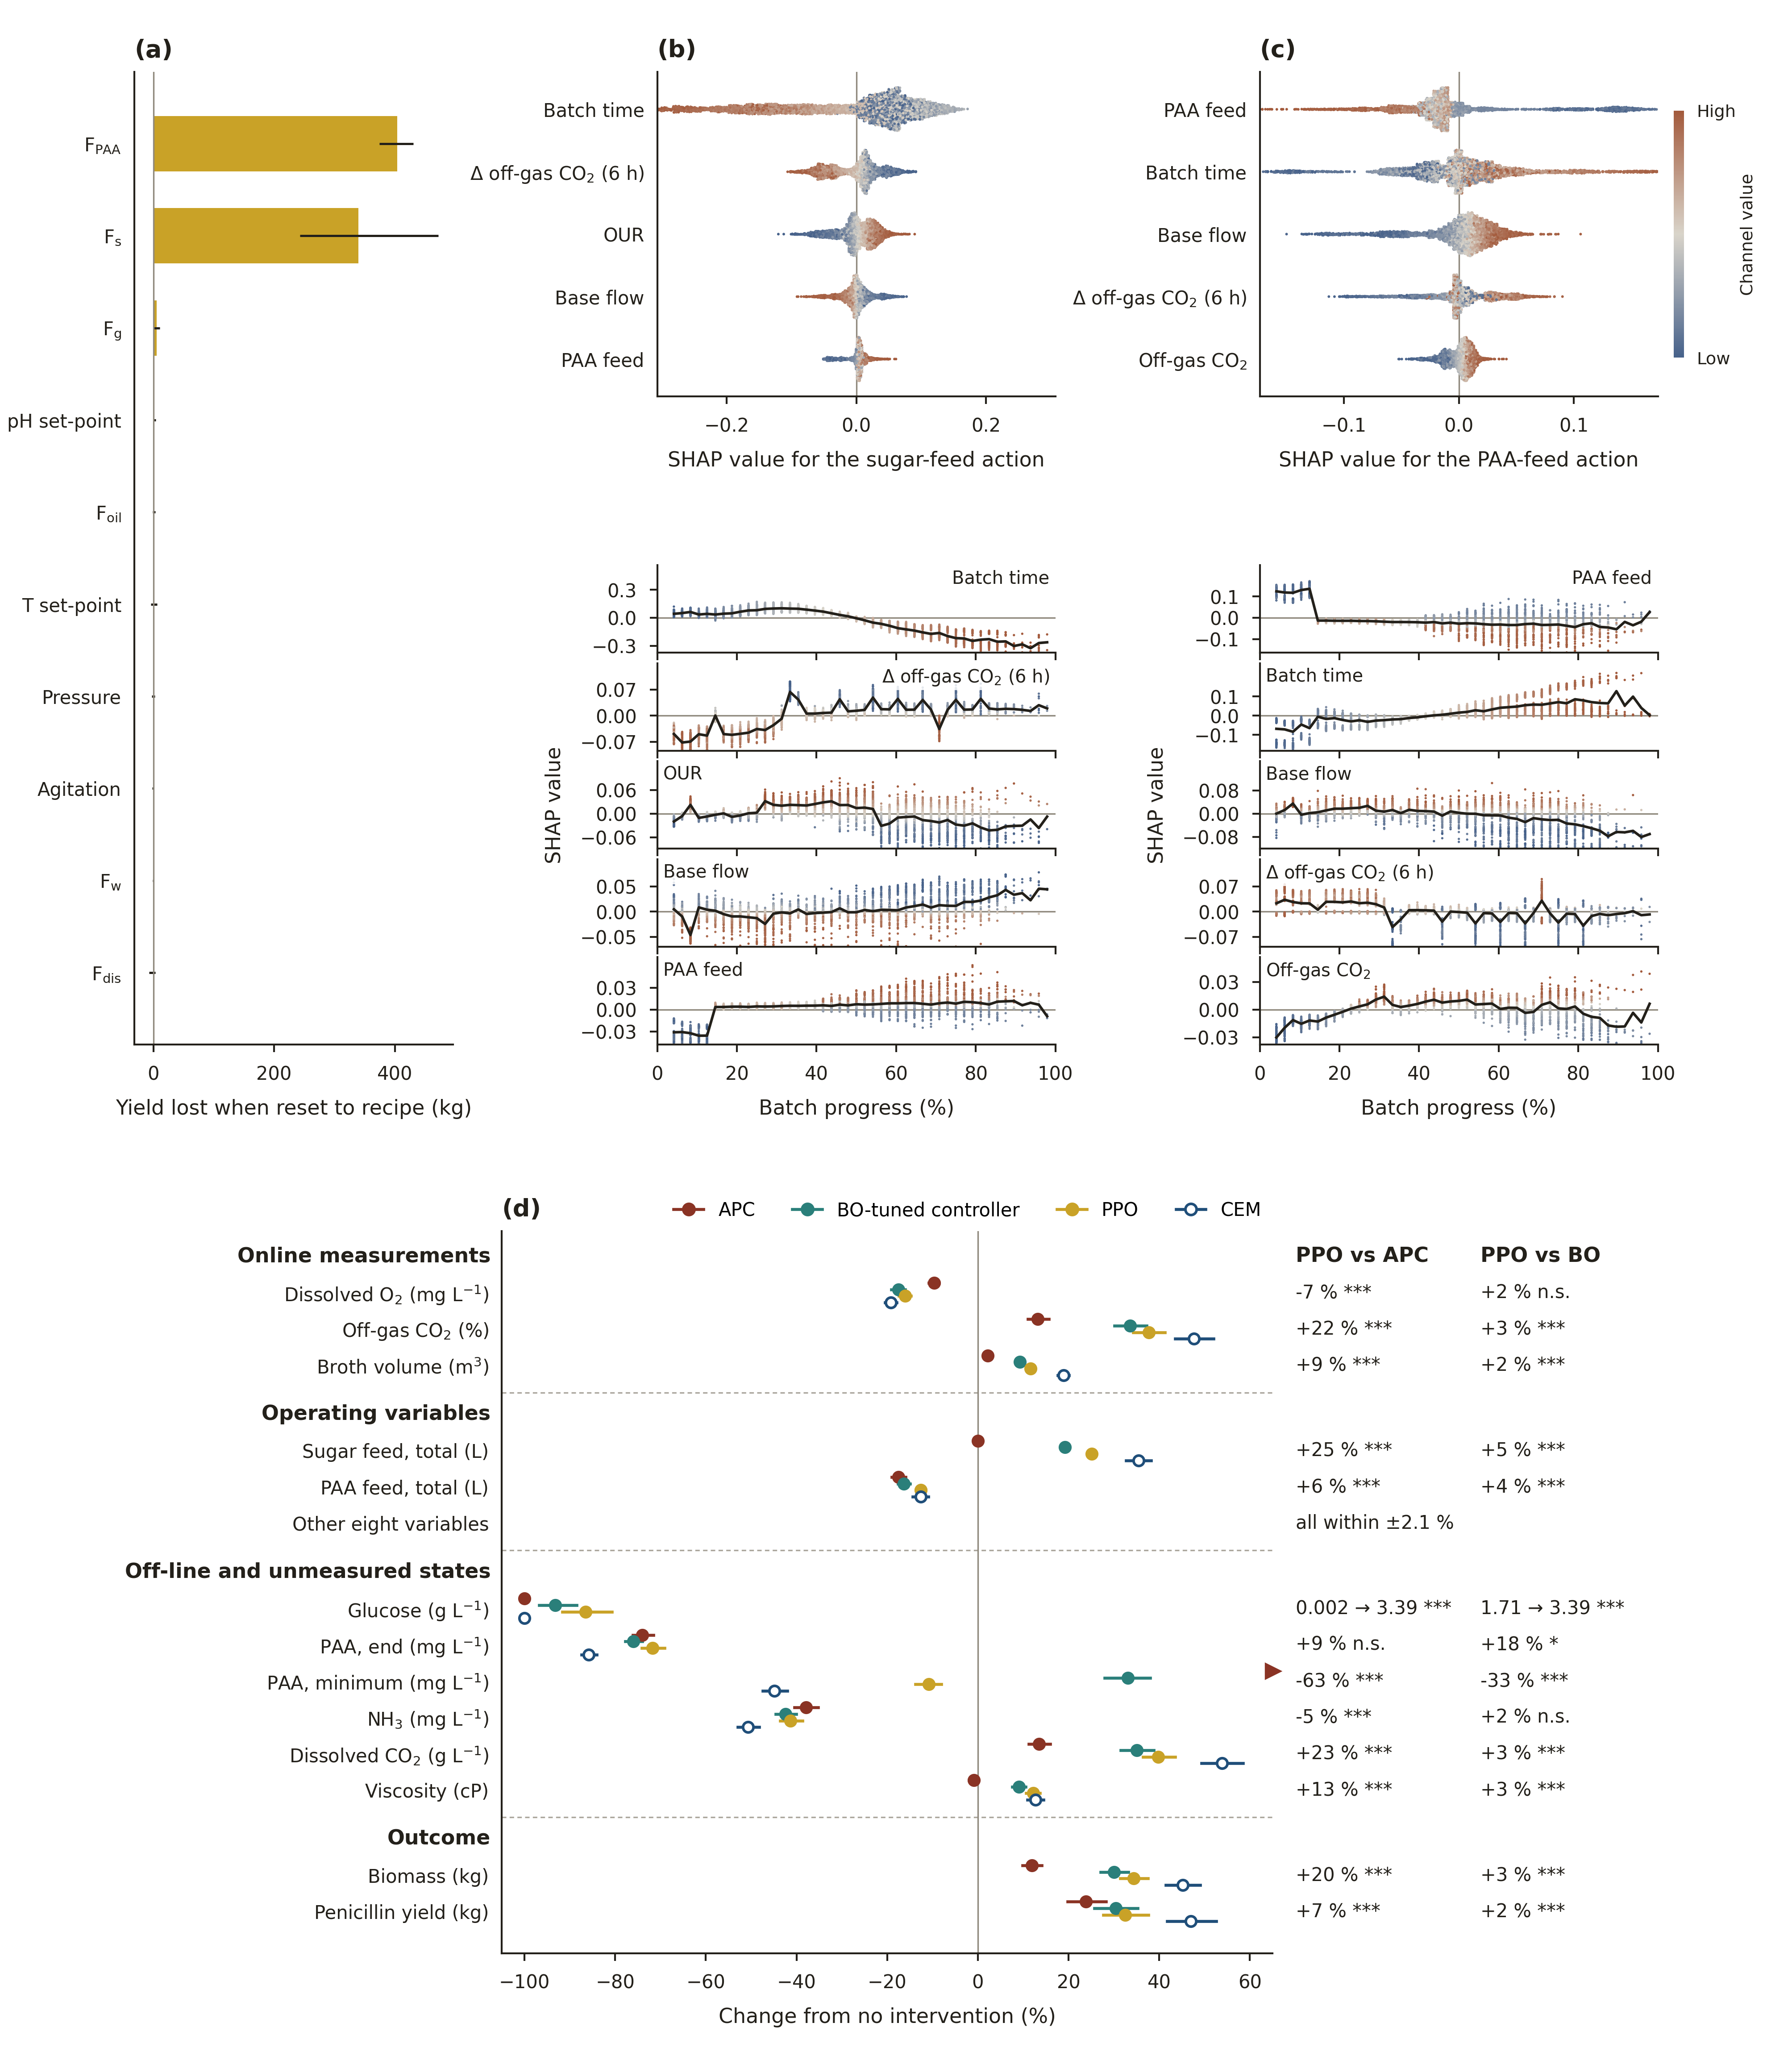

In [6]:
from IPython.display import Image
Image(OUTD + 'fig7.png', width=900)